# Backbone bake-off on EuroSAT: ResNet-50 vs ViT-S/16 vs ConvNeXt-T

**Question:** under one fixed training recipe, which backbone + init gives the best accuracy / speed trade-off on Sentinel-2 scene classification, and how does that change with label scarcity?

## Grid
| axis | values |
|---|---|
| backbone | `resnet50` (25.6M), `vit_small_patch16_224` (22.1M), `convnext_tiny` (28.6M) |
| init | **imagenet_rgb**: timm ImageNet weights, input = RGB (B04,B03,B02), `in_chans=3` — all backbones<br>**s2_ssl**: torchgeo SSL4EO-S12 MoCo weights, input = all 13 L1C bands, `in_chans=13` — ResNet-50, ViT-S<br>**imagenet_13ch**: ImageNet weights, stem stretched to 13ch (see *Models* section) — ConvNeXt-T (its 13-band row; addable to others to separate "more bands" from "in-domain pretraining") |
| mode | **lp** = linear probe (frozen backbone, cached features) · **ft** = full fine-tune |
| label fraction | 1% (≈162 imgs, ~16/class), 10% (1 620), 100% (16 200) of the train split; stratified, resampled per seed |
| seed | 0, 1, 2 (seed controls subset, head init, data order, aug) |

Weights:
- `resnet50.a1_in1k` · `vit_small_patch16_224.augreg_in21k_ft_in1k` · `convnext_tiny.fb_in22k`
- `ResNet50_Weights.SENTINEL2_ALL_MOCO` · `ViTSmall16_Weights.SENTINEL2_ALL_MOCO` (DINO also available, switch in config)
- **no S2-SSL ConvNeXt in torchgeo** → ConvNeXt's 13-band row uses `imagenet_13ch` instead.

Runs: FT = 6 (backbone,init) × 3 fractions × 3 seeds = **54**; LP = same 54 but cheap (features extracted once per backbone/init).

## Data — EuroSAT (torchgeo, 13-band L1C, 64×64, 10 classes)
- Official torchgeo split: train 16 200 / val 5 400 / test 5 400. Test only for final numbers.
- Whole dataset cached once as `int16` numpy (≈2.9 GB RAM). Batches indexed on CPU, preprocessing on GPU → no dataloader bottleneck, identical pipeline for every model.
- **Band order gotcha:** torchgeo EuroSAT stores `B8A` *last*; SSL4EO weights expect `…B08, B8A, B09…`. Cache is reordered to SSL4EO order.
- Upsampled 64→224 (bilinear) for all models: matches pretraining res, ViT pos-embeds, and makes throughput comparable. (torchgeo's own transform is resize 256 + center-crop 224; plain resize keeps the full tile.)

Normalisation (per init, matches how each was pretrained):
- `s2_ssl`: DN / 10 000 (exactly torchgeo's SSL4EO transform).
- `imagenet_rgb`: clip(DN / 3000, 0, 1) → model's own `pretrained_cfg` mean/std (**note** ViT augreg uses 0.5/0.5, not ImageNet stats).
- `imagenet_13ch`: per-band z-score with train stats (needed so the stretched stem's 3/13 scaling keeps activations at ImageNet scale).

## Recipe (identical for all backbones)
**Full FT:** AdamW, lr 2e-4, wd 0.05 (no wd on norm/bias), 5% linear warmup → cosine, label smoothing 0.1, grad-clip 1.0, bs 64, bf16 autocast, channels_last. Aug = random D4 (h-flip, v-flip, transpose = all 8 dihedral variants; orientation-invariant for nadir EO). Epochs per fraction (same for every backbone): 1% → 200, 10% → 50, 100% → 15 (≈400 / 1 250 / 3 800 steps; same epochs across fractions would give 1% only a few dozen steps). Report **last-epoch** test top-1 (no early-stopping on test).

**Linear probe:** frozen backbone in eval, pooled pre-logit features (no aug), standardised; linear head trained with AdamW (100 epochs, cosine), wd chosen from a small grid on **val** → test top-1. Standard SSL-eval protocol.

## Efficiency metrics — `imgs_per_s` helper
Synthetic batch, bs 64, 224², bf16 autocast, channels_last, warmup then timed with `cuda.synchronize`. Reports:
- inference img/s + peak memory (`max_memory_allocated`), and
- train-step img/s + peak memory (fwd+bwd+AdamW) — relevant for FT vs LP cost.

Measured for `in_chans=3` and `13` (only stem changes; difference should be tiny). Weights irrelevant to speed → random init.

## Deliverables
1. `results.csv` (one row per run, resumable) + `bench.csv`
2. Summary table: top-1 mean ± std over seeds, per (backbone, init, mode, fraction), joined with img/s & peak mem
3. Pareto plot: accuracy vs inference throughput, one panel per label fraction, frontier drawn over FT points

## Caveats
- **Pretraining mismatch across ImageNet inits:** not same data/recipe → arch effect confounded with pretraining.
  | backbone | pretrain data | labels | recipe |
  |---|---|---|---|
  | ResNet-50 `a1_in1k` | IN-1k (1.3M) | supervised | RSB A1, 600 ep |
  | ViT-S `augreg_in21k_ft_in1k` | IN-21k → IN-1k ft | supervised | AugReg |
  | ConvNeXt-T `fb_in22k` | IN-22k (14M) | supervised | ConvNeXt, 90 ep |
  | ResNet-50 / ViT-S `s2_ssl` | SSL4EO-S12 (~1M S2 patches, 13 bands) | self-sup (MoCo) | SSL4EO |

  ViT-S/ConvNeXt-T see ~10× more pretraining data than ResNet-50 → part of any ResNet gap may be data, not arch. Kept as-is: these are the standard/recommended checkpoints. Parity alternative: all IN-1k (`convnext_tiny.fb_in1k`, `vit_small_patch16_224.augreg_in1k`).
- One shared recipe ≠ each backbone's best recipe (ViTs usually want layer-decay / stronger aug).
- LP uses the full val split for wd selection even at 1% labels — slightly optimistic, applied equally to all.
- Throughput is hardware-specific; compare only within one run of this notebook.
- `cudnn.benchmark=True` for speed → runs are not bit-exact reproducible; seeds still fix subsets/init.

Set `QUICK = True` first for a ~5 min smoke test.

In [1]:
import os, site, importlib, importlib.util, time, math, json, random, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F

# timm/torchgeo missing in jupyter pod / Colab
try:
    import timm, torchgeo
except ModuleNotFoundError:
    %pip install --quiet "timm>=1.0" "torchgeo>=0.7" tabulate
    site.addsitedir(site.getusersitepackages())  # k8s pod: user site may not exist at kernel start
    importlib.invalidate_caches()
    import timm, torchgeo
from functools import partial

# bakeoff package: notebook dir if present, else shallow-clone repo to WORK_DIR (pod/Colab)
REPO, BRANCH = "https://github.com/ignaciomasari/cv_playground", "main"
WORK_DIR = "/home/jovyan/work" if os.path.isdir("/home/jovyan/work") else ".."  # PVC in pod
if importlib.util.find_spec("bakeoff") is None:
    import subprocess, sys
    src = os.path.join(WORK_DIR, "cv_playground")
    if not os.path.isdir(src):
        subprocess.run(["git", "clone", "--depth", "1", "-b", BRANCH, REPO, src], check=True)
    else:
        subprocess.run(["git", "-C", src, "pull", "--ff-only"], check=True)
    sys.path.insert(0, os.path.join(src, "backbone_bakeoff"))
import bakeoff.data as bd, bakeoff.models as bm
from bakeoff.bench import bench_backbones, imgs_per_s

DATASET_PATH = os.path.join(WORK_DIR, "data")
OUT_DIR = os.path.join(WORK_DIR, "saved_models/backbone_bakeoff")
os.makedirs(OUT_DIR, exist_ok=True)

assert torch.cuda.is_available(), "GPU needed"
device = torch.device("cuda:0")
assert torch.cuda.is_bf16_supported(), "bf16 needs Ampere+"
AMP = torch.bfloat16
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
print("torch", torch.__version__, "| timm", timm.__version__, "| torchgeo", torchgeo.__version__)
print("WORK_DIR:", os.path.abspath(WORK_DIR))

Cloning into '/home/jovyan/work/cv_playground'...


torch 2.11.0+cu128 | timm 1.0.31 | torchgeo 0.10.1
WORK_DIR: /home/jovyan/work


## Config

In [2]:
QUICK = False  # True: smoke test (1 seed, 10%, few epochs)

# backbone registry (arch, ImageNet tag, S2 weights, inits): bakeoff/models.py
BACKBONES = bm.BACKBONES
in_chans_of, available = bm.in_chans_of, bm.available
# add "imagenet_13ch" to resnet/vit inits to disentangle bands vs pretraining
INITS = list(dict.fromkeys(i for c in BACKBONES.values() for i in c["inits"]))
MODES = ["lp", "ft"]
FRACTIONS = [0.01, 0.1, 1.0]
SEEDS = [0, 1, 2]

NUM_CLASSES = 10
IMG_SIZE = 224
BS = 64
# FT recipe (shared)
LR, WD, WARMUP_FRAC, LABEL_SMOOTH, CLIP = 2e-4, 0.05, 0.05, 0.1, 1.0
EPOCHS_FT = {0.01: 200, 0.1: 50, 1.0: 15}
# LP recipe (shared)
LP_EPOCHS, LP_LR, LP_BS, LP_WD_GRID = 100, 1e-3, 256, [0.0, 1e-4, 1e-3, 1e-2]
RGB_DN_MAX = bd.RGB_DN_MAX  # L1C DN -> [0,1] for RGB/ImageNet path; edit in bakeoff/data.py

if QUICK:
    SEEDS, FRACTIONS = [0], [0.1]
    EPOCHS_FT = {0.1: 2}
    LP_EPOCHS = 10
    OUT_DIR = os.path.join(OUT_DIR, "quick"); os.makedirs(OUT_DIR, exist_ok=True)

RESULTS_CSV = os.path.join(OUT_DIR, "results.csv")
BENCH_CSV = os.path.join(OUT_DIR, "bench.csv")


def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

## Data: download + cache EuroSAT as int16 in SSL4EO band order
First run downloads ~2 GB and reads 27k GeoTIFFs once (few minutes); afterwards loads from `.npy`.

In [3]:
# int16 cache in SSL4EO band order (B8A moved after B08): bakeoff/data.py
SSL_ORDER, RGB_IDX = bd.SSL_ORDER, bd.RGB_IDX
EUROSAT_ROOT = os.path.join(DATASET_PATH, "eurosat")

DATA = bd.load_eurosat(EUROSAT_ROOT, num_workers=min(4, os.cpu_count() or 1))
for s, (x, y) in DATA.items():
    print(f"{s:5s} x{tuple(x.shape)} {x.dtype}  classes={y.bincount().tolist()}")
CLASSES = bd.class_names(EUROSAT_ROOT)
print(CLASSES)

# per-band DN stats (train) for imagenet_13ch z-score
BAND_MEAN, BAND_STD = bd.band_stats(DATA["train"][0])

train x(16200, 13, 64, 64) torch.int16  classes=[1791, 1787, 1799, 1505, 1492, 1195, 1481, 1863, 1460, 1827]
val   x(5400, 13, 64, 64) torch.int16  classes=[613, 605, 628, 499, 507, 409, 481, 583, 511, 564]
test  x(5400, 13, 64, 64) torch.int16  classes=[596, 608, 573, 496, 501, 396, 538, 554, 529, 609]
['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


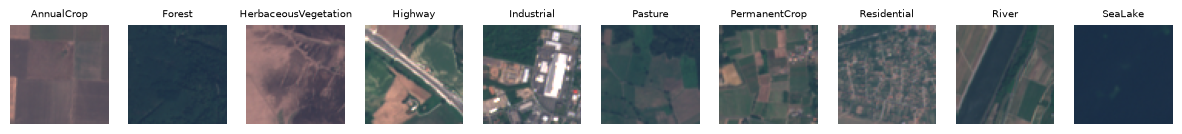

In [31]:
# sanity: RGB previews
x, y = DATA["train"]
fig, axs = plt.subplots(1, 10, figsize=(15, 2))
for c, ax in enumerate(axs):
    i = (y == c).nonzero()[0, 0]
    ax.imshow((x[i, RGB_IDX].float() / RGB_DN_MAX).clamp(0, 1).permute(1, 2, 0)); ax.set_title(CLASSES[c], fontsize=7); ax.axis("off")
plt.show()

## Stratified label subsets
Same `(fraction, seed)` → same subset for every backbone/init/mode → paired comparison.

In [32]:
def subset_idx(frac, seed):
    return bd.subset_idx(DATA["train"][1], frac, seed, NUM_CLASSES)

for f in FRACTIONS: print(f, len(subset_idx(f, 0)))

0.01 163
0.1 1620
1.0 16200


## Models + per-init input spec
`build(bb, init, num_classes)` → `(model, spec)`. `spec` = bands, scale, clip, mean, std used by `prep` on GPU.
S2-SSL weights loaded into a plain timm model (same as `torchgeo.models.resnet50(weights=...)` does internally), with a check that only head/final-norm keys are missing.

### `imagenet_13ch`: stretching an RGB stem to 13 bands
`timm.create_model(..., pretrained=True, in_chans=13)` loads all ImageNet weights unchanged except the first conv (ConvNeXt `stem.0`: 4×4 stride-4, weight `[96, 3, 4, 4]` → `[96, 13, 4, 4]`), adapted by `timm.models.adapt_input_conv`:
```python
w = w.repeat(1, ceil(13 / 3), 1, 1)[:, :13]  # tile R,G,B filter slices cyclically
w *= 3 / 13                                   # keep output magnitude
```
Band *i* (SSL order) gets the filter slice of RGB channel *i mod 3*:

| band | B01 | B02 | B03 | B04 | B05 | B06 | B07 | B08 | B8A | B09 | B10 | B11 | B12 |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| filter | R | G | B | R | G | B | R | G | B | R | G | B | R |

- Why 3/13: a stem output is Σ over input channels. With inputs of similar stats (per-band z-score), 13 terms instead of 3 would blow up activations ~13/3×; the rescale keeps the first feature map at ImageNet scale so the pretrained norms/blocks downstream still see familiar statistics.
- Effect: at step 0 each output ≈ the RGB filter response averaged over "pseudo-R/G/B" band groups — not the true RGB image (B02/B03 get G/B, not B/G). Positional, not spectral, mapping. FT learns to re-weight bands; LP is stuck with this mix.
- Rest of the network (stages, norms) = ImageNet-22k weights; head = new random 10-class layer.

In [33]:
# model building + input prep: bakeoff/models.py (tested in tests/test_models.py)
build = partial(bm.build, num_classes=NUM_CLASSES, device=device, band_mean=BAND_MEAN, band_std=BAND_STD)
prep = partial(bm.prep, img_size=IMG_SIZE)
iterate = bd.iterate

@torch.inference_mode()
def evaluate(model, spec, split, bs=256):
    model.eval(); x, y = DATA[split]; correct = 0
    for b in iterate(len(y), bs, False):
        with torch.autocast("cuda", dtype=AMP):
            correct += (model(prep(x[b], spec, False)).argmax(1).cpu() == y[b]).sum().item()
    return correct / len(y)

# smoke: every available (backbone, init) builds
for bb in BACKBONES:
    for init in INITS:
        if available(bb, init):
            m, s = build(bb, init); print(f"{bb:10s} {init:13s} params={sum(p.numel() for p in m.parameters())/1e6:.1f}M in_chans={in_chans_of(init)}")
            del m
torch.cuda.empty_cache()

resnet50   imagenet_rgb  params=23.5M in_chans=3
resnet50   s2_ssl        params=23.6M in_chans=13
vit_s16    imagenet_rgb  params=21.7M in_chans=3
vit_s16    s2_ssl        params=22.7M in_chans=13
convnext_t imagenet_rgb  params=27.8M in_chans=3
convnext_t imagenet_13ch params=27.8M in_chans=13


## `imgs_per_s` — throughput + peak memory
bs 64, 224², bf16, channels_last. `train=False` → inference (`inference_mode`); `train=True` → fwd + bwd + AdamW step.

In [34]:
# imgs_per_s / bench_backbones: bakeoff/bench.py (also CLI: python -m bakeoff.bench --out bench.csv)
bench = bench_backbones(list(BACKBONES), num_classes=NUM_CLASSES, bs=BS, img=IMG_SIZE, device=device)
bench.to_csv(BENCH_CSV, index=False)
bench.round(1)

,backbone,in_chans,params_M,infer_ips,infer_mem_MB,train_ips,train_mem_MB
0,resnet50,3,23.5,6750.6,510.2,1970.7,3139.5
1,resnet50,13,23.6,6476.4,633.6,1916.7,3321.5
2,vit_s16,3,21.7,8181.3,332.5,2487.3,2528.1
3,vit_s16,13,22.7,7859.6,505.0,2399.0,2724.6
4,convnext_t,3,27.8,3458.0,726.3,1275.0,4291.5
5,convnext_t,13,27.8,3399.2,849.1,1260.1,4476.8


## Linear probe
Features extracted once per (backbone, init) for all splits (frozen, eval, no aug) → cached to disk. Head training per (fraction, seed) takes seconds.

In [35]:
@torch.inference_mode()
def extract(bb, init):
    path = os.path.join(OUT_DIR, f"feats_{bb}_{init}.pt")
    if os.path.isfile(path): return torch.load(path)
    m, spec = build(bb, init, num_classes=0); m.eval()  # num_classes=0 -> pooled pre-logits
    feats = {}
    for split, (x, y) in DATA.items():
        out = []
        for b in iterate(len(y), 256, False):
            with torch.autocast("cuda", dtype=AMP):
                out.append(m(prep(x[b], spec, False)).float().cpu())
        feats[split] = torch.cat(out)
    del m; torch.cuda.empty_cache()
    torch.save(feats, path)
    return feats

def train_linear(Xtr, ytr, wd, seed):
    seed_all(seed)
    head = nn.Linear(Xtr.size(1), NUM_CLASSES).to(device)
    opt = torch.optim.AdamW(head.parameters(), lr=LP_LR, weight_decay=wd)
    bs = min(LP_BS, len(ytr)); steps = LP_EPOCHS * math.ceil(len(ytr) / bs)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    for _ in range(LP_EPOCHS):
        for b in iterate(len(ytr), bs, True):
            loss = F.cross_entropy(head(Xtr[b]), ytr[b])
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sched.step()
    return head

@torch.no_grad()
def acc(head, X, y): return (head(X).argmax(1) == y).float().mean().item()

def linear_probe(feats, frac, seed):
    idx = torch.from_numpy(subset_idx(frac, seed))
    Xtr, ytr = feats["train"][idx].to(device), DATA["train"][1][idx].to(device)
    mu, sd = Xtr.mean(0), Xtr.std(0) + 1e-6  # standardise w/ subset stats
    norm = lambda s: ((feats[s].to(device) - mu) / sd, DATA[s][1].to(device))
    Xtr = (Xtr - mu) / sd; Xva, yva = norm("val"); Xte, yte = norm("test")
    best = max(((acc(h := train_linear(Xtr, ytr, wd, seed), Xva, yva), wd, h) for wd in LP_WD_GRID), key=lambda t: t[0])
    return dict(top1_val=best[0], top1_test=acc(best[2], Xte, yte), lp_wd=best[1], n_train=len(idx))

## Full fine-tune

In [36]:
def param_groups(model, wd):
    decay, no_decay = [], []
    for n, p in model.named_parameters():
        (no_decay if p.ndim <= 1 or n.endswith((".bias", "pos_embed", "cls_token")) else decay).append(p)
    return [{"params": decay, "weight_decay": wd}, {"params": no_decay, "weight_decay": 0.0}]

def finetune(bb, init, frac, seed):
    seed_all(seed)
    model, spec = build(bb, init)
    idx = torch.from_numpy(subset_idx(frac, seed))
    x, y = DATA["train"][0][idx], DATA["train"][1][idx]
    steps_per_ep = max(1, len(y) // BS); total = steps_per_ep * EPOCHS_FT[frac]
    warm = max(1, int(WARMUP_FRAC * total))
    opt = torch.optim.AdamW(param_groups(model, WD), lr=LR)
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm))))
    crit = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTH)
    gc.collect(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    t0 = time.perf_counter(); model.train()
    for ep in range(EPOCHS_FT[frac]):
        for b in iterate(len(y), BS, True, drop_last=True):
            with torch.autocast("cuda", dtype=AMP):
                loss = crit(model(prep(x[b], spec, True)), y[b].to(device, non_blocking=True))
            opt.zero_grad(set_to_none=True); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), CLIP)
            opt.step(); sched.step()
    torch.cuda.synchronize()
    out = dict(train_time_s=time.perf_counter() - t0, train_peak_mem_MB=torch.cuda.max_memory_allocated() / 2**20,
               final_loss=loss.item(), top1_val=evaluate(model, spec, "val"), top1_test=evaluate(model, spec, "test"),
               n_train=len(y), steps=total)
    del model, opt; gc.collect(); torch.cuda.empty_cache()
    return out

## Run the grid (resumable)
Each finished run is appended to `results.csv`; re-running the cell skips completed `(backbone, init, mode, frac, seed)` keys.

In [37]:
KEY = ["backbone", "init", "mode", "frac", "seed"]
# fixed schema: LP/FT rows share header; non-applicable cols = NaN
RESULT_COLS = KEY + ["in_chans", "n_train", "top1_val", "top1_test",
                     "lp_wd",                                                        # LP only
                     "steps", "final_loss", "train_time_s", "train_peak_mem_MB"]     # FT only

def read_results():
    # header mismatch (old/corrupt file) -> move aside, start fresh
    if not os.path.isfile(RESULTS_CSV): return None
    with open(RESULTS_CSV) as f: header = f.readline().strip().split(",")
    if header != RESULT_COLS:
        os.replace(RESULTS_CSV, RESULTS_CSV + ".bak"); print("schema mismatch -> moved to", RESULTS_CSV + ".bak")
        return None
    return pd.read_csv(RESULTS_CSV)

def log(row):
    pd.DataFrame([row]).reindex(columns=RESULT_COLS).to_csv(
        RESULTS_CSV, mode="a", header=not os.path.isfile(RESULTS_CSV), index=False)

prev = read_results()
done = set() if prev is None else set(map(tuple, prev[KEY].astype({"frac": float, "seed": int}).values.tolist()))

jobs = [(bb, init, mode, frac, seed) for bb in BACKBONES for init in INITS if available(bb, init)
        for mode in MODES for frac in FRACTIONS for seed in SEEDS]
todo = [j for j in jobs if j not in done]
print(f"{len(jobs)} runs, {len(todo)} to do")

feats_cache = {}
for bb, init, mode, frac, seed in (pbar := tqdm(todo)):
    pbar.set_description(f"{bb}|{init}|{mode}|{frac}|s{seed}")
    if mode == "lp":
        if (bb, init) not in feats_cache:
            feats_cache.clear(); feats_cache[(bb, init)] = extract(bb, init)
        r = linear_probe(feats_cache[(bb, init)], frac, seed)
    else:
        r = finetune(bb, init, frac, seed)
    row = dict(zip(KEY, (bb, init, mode, frac, seed)), **r, in_chans=in_chans_of(init))
    log(row); print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in row.items()})

108 runs, 96 to do


  0%|          | 0/96 [00:00<?, ?it/s]

{'backbone': 'resnet50', 'init': 'imagenet_rgb', 'mode': 'lp', 'frac': 0.01, 'seed': 0, 'top1_val': 0.7956, 'top1_test': 0.7981, 'lp_wd': 0.0, 'n_train': 163, 'in_chans': 3}
{'backbone': 'resnet50', 'init': 'imagenet_rgb', 'mode': 'lp', 'frac': 0.01, 'seed': 1, 'top1_val': 0.7659, 'top1_test': 0.7626, 'lp_wd': 0.0, 'n_train': 163, 'in_chans': 3}
{'backbone': 'resnet50', 'init': 'imagenet_rgb', 'mode': 'lp', 'frac': 0.01, 'seed': 2, 'top1_val': 0.7917, 'top1_test': 0.7994, 'lp_wd': 0.001, 'n_train': 163, 'in_chans': 3}
{'backbone': 'resnet50', 'init': 'imagenet_rgb', 'mode': 'lp', 'frac': 0.1, 'seed': 1, 'top1_val': 0.9137, 'top1_test': 0.9157, 'lp_wd': 0.0, 'n_train': 1620, 'in_chans': 3}
{'backbone': 'resnet50', 'init': 'imagenet_rgb', 'mode': 'lp', 'frac': 0.1, 'seed': 2, 'top1_val': 0.9115, 'top1_test': 0.9172, 'lp_wd': 0.0, 'n_train': 1620, 'in_chans': 3}
{'backbone': 'resnet50', 'init': 'imagenet_rgb', 'mode': 'lp', 'frac': 1.0, 'seed': 0, 'top1_val': 0.9481, 'top1_test': 0.9513, 

## Results table — top-1 (test) mean ± std over seeds + efficiency

In [38]:
res = pd.read_csv(RESULTS_CSV)
bench = pd.read_csv(BENCH_CSV)

agg = (res.groupby(["backbone", "init", "in_chans", "mode", "frac"])
          .agg(top1=("top1_test", "mean"), std=("top1_test", "std"), n=("seed", "count"),
               ft_mem_MB=("train_peak_mem_MB", "max"), ft_time_s=("train_time_s", "mean"))
          .reset_index())
agg = agg.merge(bench[["backbone", "in_chans", "params_M", "infer_ips", "infer_mem_MB", "train_ips", "train_mem_MB"]],
                on=["backbone", "in_chans"], how="left")
agg.to_csv(os.path.join(OUT_DIR, "summary_long.csv"), index=False)

fmt = lambda r: f"{100*r.top1:.1f} ± {100*(r['std'] if r['std'] == r['std'] else 0):.1f}"
table = (agg.assign(cell=agg.apply(fmt, axis=1), col=agg["mode"].str.upper() + " " + (100 * agg.frac).map("{:g}%".format))
            .pivot_table(index=["backbone", "init"], columns="col", values="cell", aggfunc="first"))
eff = (bench.set_index(["backbone", "in_chans"])
            [["params_M", "infer_ips", "infer_mem_MB", "train_ips", "train_mem_MB"]].round(0))
idx = table.index.to_frame(index=False).assign(in_chans=lambda d: d.init.map(in_chans_of))
table = table.join(pd.DataFrame(eff.loc[list(zip(idx.backbone, idx.in_chans))].values,
                                index=table.index, columns=eff.columns))
table.to_csv(os.path.join(OUT_DIR, "summary_table.csv"))
print(f"bs {BS} | {IMG_SIZE}px | bf16")
try:
    md_tbl = table.to_markdown(); open(os.path.join(OUT_DIR, "summary_table.md"), "w").write(md_tbl)
except ImportError:
    pass
table

bs 64 | 224px | bf16


FT 1%       FT 10%     FT 100%       LP 1%  \
backbone   init                                                             
convnext_t imagenet_13ch  92.9 ± 1.0   96.9 ± 1.9  99.2 ± 0.0  81.6 ± 0.5   
           imagenet_rgb   94.2 ± 0.9   97.4 ± 1.0  99.3 ± 0.1  85.3 ± 1.1   
resnet50   imagenet_rgb   90.5 ± 1.1  85.6 ± 20.5  99.0 ± 0.0  78.7 ± 2.1   
           s2_ssl         93.0 ± 2.6   97.6 ± 1.3  99.4 ± 0.1  91.5 ± 1.4   
vit_s16    imagenet_rgb   93.0 ± 1.0   97.0 ± 1.0  99.0 ± 0.1  84.3 ± 2.2   
           s2_ssl         91.1 ± 1.5  91.1 ± 10.0  98.7 ± 0.1  91.1 ± 1.6   

                              LP 10%     LP 100%  params_M  infer_ips  \
backbone   init                                                         
convnext_t imagenet_13ch  90.9 ± 1.8  95.1 ± 0.1      28.0     3399.0   
           imagenet_rgb   92.5 ± 1.3  95.8 ± 0.1      28.0     3458.0   
resnet50   imagenet_rgb   91.0 ± 1.1  95.2 ± 0.0      24.0     6751.0   
           s2_ssl         96.5 ± 0.3  98.5 ± 0.0      24.0     6476.0   
vit_s16    imagenet_rgb   91.2 ± 3.1  95.9 ± 0.0      22.0     8181.0   
           s2_ssl         95.1 ± 2.1  97.9 ± 0.0      23.0     7860.0   

                          infer_mem_MB  train_ips  train_mem_MB  
backbone   init                                                  
convnext_t imagenet_13ch         849.0     1260.0        4477.0  
           imagenet_rgb          726.0     1275.0        4291.0  
resnet50   imagenet_rgb          510.0     1971.0        3139.0  
           s2_ssl                634.0     1917.0        3322.0  
vit_s16    imagenet_rgb          332.0     2487.0        2528.0  
           s2_ssl                505.0     2399.0        2725.0

In [39]:
# FT - LP gap (pp) and paired seed-wise deltas: s2_ssl vs imagenet_rgb
piv = res.pivot_table(index=["backbone", "init", "frac", "seed"], columns="mode", values="top1_test")
if {"ft", "lp"} <= set(piv.columns):
    gap = (100 * (piv.ft - piv.lp)).groupby(["backbone", "init", "frac"]).agg(["mean", "std"]).round(2)
    display(gap.rename(columns=lambda c: f"FT-LP {c}"))
p2 = res.pivot_table(index=["backbone", "mode", "frac", "seed"], columns="init", values="top1_test")
if {"s2_ssl", "imagenet_rgb"} <= set(p2.columns):
    d = (100 * (p2.s2_ssl - p2.imagenet_rgb)).dropna().groupby(["backbone", "mode", "frac"]).agg(["mean", "std"]).round(2)
    display(d.rename(columns=lambda c: f"S2SSL-INrgb {c}"))

FT-LP mean  FT-LP std
backbone   init          frac                       
convnext_t imagenet_13ch 0.01       11.30       0.80
                         0.10        5.97       0.21
                         1.00        4.04       0.05
           imagenet_rgb  0.01        8.83       0.59
                         0.10        4.87       0.31
                         1.00        3.49       0.15
resnet50   imagenet_rgb  0.01       11.80       1.75
                         0.10       -5.40      19.36
                         1.00        3.81       0.04
           s2_ssl        0.01        1.47       2.35
                         0.10        1.10       1.00
                         1.00        0.91       0.10
vit_s16    imagenet_rgb  0.01        8.72       1.20
                         0.10        5.73       2.11
                         1.00        3.09       0.06
           s2_ssl        0.01       -0.01       2.38
                         0.10       -4.00       7.91
                         1.00        0.75       0.07

S2SSL-INrgb mean  S2SSL-INrgb std
backbone mode frac                                   
resnet50 ft   0.01              2.51             1.99
              0.10             11.98            19.18
              1.00              0.41             0.10
         lp   0.01             12.83             2.18
              0.10              5.48             0.80
              1.00              3.31             0.03
vit_s16  ft   0.01             -1.94             0.53
              0.10             -5.85             9.02
              1.00             -0.31             0.18
         lp   0.01              6.78             2.75
              0.10              3.89             1.00
              1.00              2.02             0.07

## Pareto plot — accuracy vs inference throughput
One panel per label fraction. Colour = backbone, marker = init, filled = FT, hollow = LP, error bars = std over seeds. Dashed line = Pareto frontier over FT points (no other point is both faster and more accurate).

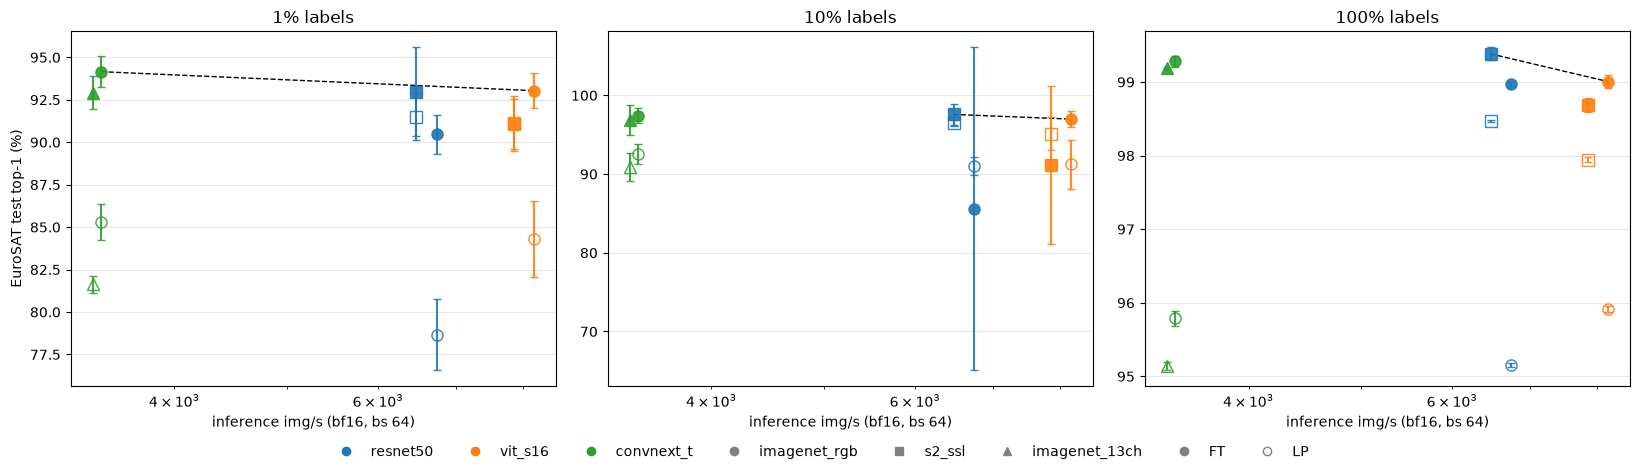

In [40]:
def pareto(df, x="infer_ips", y="top1"):
    pts = df.sort_values(x, ascending=False); best, keep = -1, []
    for _, r in pts.iterrows():
        if r[y] > best: keep.append(r); best = r[y]
    return pd.DataFrame(keep).sort_values(x)

COL = dict(zip(BACKBONES, plt.cm.tab10.colors))
MK = {"imagenet_rgb": "o", "s2_ssl": "s", "imagenet_13ch": "^"}
fracs = sorted(agg.frac.unique())
fig, axs = plt.subplots(1, len(fracs), figsize=(5.5 * len(fracs), 4.5), sharex=True, squeeze=False)
for ax, f in zip(axs[0], fracs):
    d = agg[agg.frac == f]
    for _, r in d.iterrows():
        filled = r["mode"] == "ft"
        ax.errorbar(r.infer_ips, 100 * r.top1, yerr=100 * np.nan_to_num(r["std"]), fmt=MK.get(r.init, "x"), ms=8,
                    color=COL[r.backbone], mfc=COL[r.backbone] if filled else "none", capsize=3, alpha=0.9)
    fr = pareto(d[d["mode"] == "ft"])
    if len(fr): ax.plot(fr.infer_ips, 100 * fr.top1, "k--", lw=1, zorder=0)
    ax.set_xscale("log"); ax.set_title(f"{100*f:g}% labels"); ax.set_xlabel(f"inference img/s (bf16, bs {BS})")
    ax.grid(alpha=0.3)
axs[0, 0].set_ylabel("EuroSAT test top-1 (%)")
from matplotlib.lines import Line2D
h = [Line2D([], [], color=c, marker="o", ls="", label=b) for b, c in COL.items()] + \
    [Line2D([], [], color="gray", marker=m, ls="", label=i) for i, m in MK.items() if i in INITS] + \
    [Line2D([], [], color="gray", marker="o", ls="", label="FT"), Line2D([], [], color="gray", marker="o", mfc="none", ls="", label="LP")]
fig.legend(handles=h, loc="lower center", ncol=len(h), frameon=False, bbox_to_anchor=(0.5, -0.06))
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "pareto.png"), dpi=200, bbox_inches="tight")
plt.show()

## Reading the results (fill in after running)
Things to check / expected patterns to confirm or refute:
- **Label efficiency:** S2-SSL init should help most at 1% and in **LP** (in-domain features, all 13 bands); gap shrinks at 100% FT.
- **LP vs FT:** ImageNet-RGB features usually have a large FT−LP gap on EuroSAT; SSL4EO features a smaller one.
- **Bands vs pretraining:** if `imagenet_13ch` is enabled, `imagenet_13ch − imagenet_rgb` isolates the value of extra bands; `s2_ssl − imagenet_13ch` isolates in-domain pretraining.
- **Speed:** at 224² ResNet-50 and ConvNeXt-T are typically close; ViT-S/16 (196 tokens) is often the fastest in bf16 on recent GPUs. Stem `in_chans` 3→13 should barely move img/s.
- **Pareto:** state which configs sit on the frontier per label regime, and the recommendation for a deployment that needs X img/s.